## Proporción de población urbana viviendo en barrios marginales

In [1]:
import os
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import dash
from dash import dcc
from dash import html

### Tip 1: Entiende a la audiencia

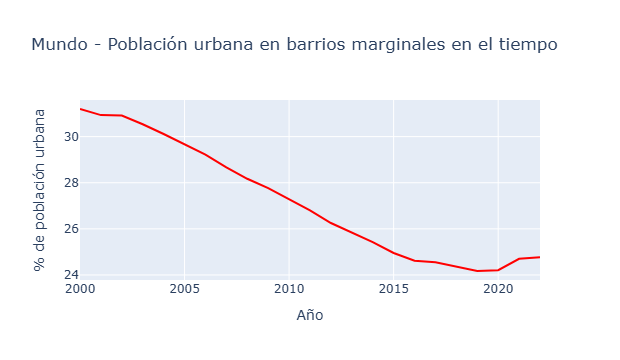

In [3]:
df = pd.read_csv("EN_LND_SLUM.csv")

df_world = df[df["GEOGRAPHY"] == "G00100000"].sort_values("TIME_PERIOD")

fig1 = go.Figure()
fig1.add_trace(go.Scatter(
    x=df_world["TIME_PERIOD"],
    y=df_world["OBS_VALUE"],
    mode="lines",
    name="Mundo",
    line=dict(color="red")
))
fig1.update_layout(
    title="Mundo - Población urbana en barrios marginales en el tiempo",
    xaxis_title="Año",
    yaxis_title="% de población urbana"
)
fig1.show()

### Tip 2: Usar la visualización correcta

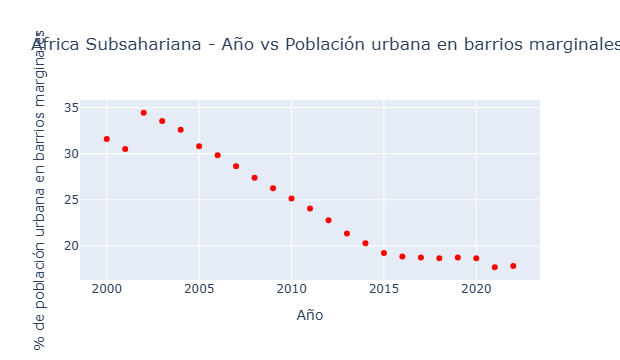

In [4]:
# Serie de África Subsahariana (G00103000), anual 2000–2022
df_africa = df[df["GEOGRAPHY"] == "G00103000"].sort_values("TIME_PERIOD")

#Grafica de dispersión de año vs proporción de barrios marginales
fig2 = go.Figure()
fig2.add_trace(go.Scatter(
    x=df_africa["TIME_PERIOD"],
    y=df_africa["OBS_VALUE"],
    mode="markers",
    name="Año vs % barrios marginales",
    marker=dict(color="red")
))
fig2.update_layout(
    title="África Subsahariana - Año vs Población urbana en barrios marginales",
    xaxis_title="Año",
    yaxis_title="% de población urbana en barrios marginales"
)
fig2.show()

### Tip 3: Enfatizar en los puntos clave

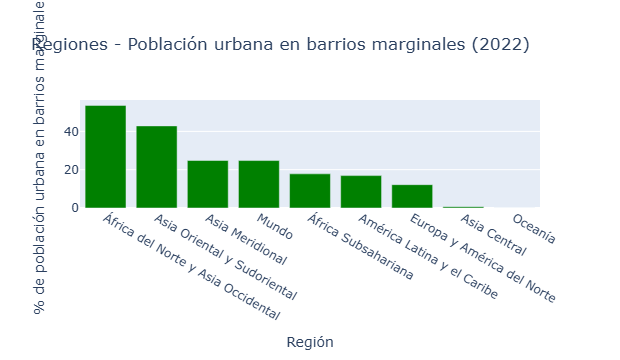

In [5]:
# Agregados regionales en 2022
regiones = {
    "G00100000": "Mundo",
    "G00103000": "África Subsahariana",
    "G00104000": "África del Norte y Asia Occidental",
    "G00116000": "Asia Oriental y Sudoriental",
    "G00122000": "Asia Meridional",
    "G00126000": "Asia Central",
    "G00137000": "América Latina y el Caribe",
    "G00144000": "Oceanía",
    "G00145000": "Europa y América del Norte",
}

df_reg = df[df["GEOGRAPHY"].isin(regiones.keys())].copy()
df_reg["Region"] = df_reg["GEOGRAPHY"].map(regiones)

df_2022 = (df_reg[df_reg["TIME_PERIOD"] == 2022]
           .sort_values("OBS_VALUE", ascending=False))

#Grafica de barras para proporción de barrios marginales por región (2022)
fig3 = go.Figure()
fig3.add_trace(go.Bar(
    x=df_2022["Region"],
    y=df_2022["OBS_VALUE"],
    name="% barrios marginales (2022)",
    marker=dict(color="green")
))
fig3.update_layout(
    title="Regiones - Población urbana en barrios marginales (2022)",
    xaxis_title="Región",
    yaxis_title="% de población urbana en barrios marginales"
)
fig3.show()

### Tip 4: Cuenta una historia con tus datos

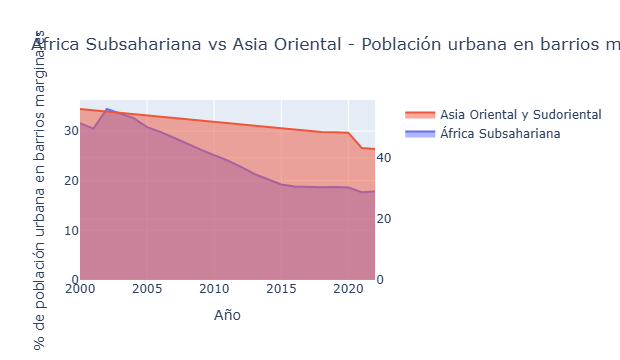

In [6]:
# Series de África Subsahariana y Asia Oriental (anual 2000–2022)
df_africa = df[df["GEOGRAPHY"] == "G00103000"].sort_values("TIME_PERIOD")
df_easia  = df[df["GEOGRAPHY"] == "G00116000"].sort_values("TIME_PERIOD")

# Creación de gráfico de área apilada con doble eje para dos regiones
fig4 = make_subplots(specs=[[{"secondary_y": True}]])
fig4.add_trace(
    go.Scatter(x=df_africa["TIME_PERIOD"], y=df_africa["OBS_VALUE"],
               mode='lines', name='África Subsahariana', stackgroup='one'),
    secondary_y=False
)
fig4.add_trace(
    go.Scatter(x=df_easia["TIME_PERIOD"], y=df_easia["OBS_VALUE"],
               mode='lines', name='Asia Oriental y Sudoriental', stackgroup='one'),
    secondary_y=True
)
fig4.update_layout(
    title='África Subsahariana vs Asia Oriental - Población urbana en barrios marginales en el tiempo',
    xaxis_title='Año',
    yaxis_title='% de población urbana en barrios marginales'
)
fig4.show()

In [9]:
# Consolidación de gráficos

app = dash.Dash(__name__)
app.layout = html.Div([
    html.H1('Cuadro de Control de Mando (Dashboard)'),
    
    html.Div([
        dcc.Graph(figure=fig1),
        dcc.Graph(figure=fig2),
    ], style={'display': 'flex'}),
    
    html.Div([
        dcc.Graph(figure=fig3),
        dcc.Graph(figure=fig4),
    ], style={'display': 'flex'}),
])

if __name__ == '__main__':
    app.run(debug=True,port=8051)